<font size=7 color="#5499C7" >Final Project</font>
- <font size=5>__Group Members__ : Kourosh Sajjadi - Kasra Noorbakhsh</font>
- <font size=5>__Student IDs__  : 810100587 - 810100230</font> 
- <font size=5>__Course__ : Computer Vision</font> 

In [ ]:
# Reproducibility
SEED = 42
DETERMINISTIC = False

# Runtime controls
FAST_RUN = False  # True: smaller subset + lower resolution for quick smoke tests
EPOCHS = 15
MIXED_PRECISION = True

# Task selection
TASK = "restore"

# Dataset selection
DATASET_SLUG = "vikramtiwari/pix2pix-dataset"
DATASET_NAME = "edges2shoes"
DIRECTION = "AtoB"

# Image sizes and batching
FULL_IMG_SIZE = 256
FAST_IMG_SIZE = 256
IMG_SIZE = FAST_IMG_SIZE if FAST_RUN else FULL_IMG_SIZE

FULL_BATCH_SIZE = 16
FAST_BATCH_SIZE = 4
BATCH_SIZE = FAST_BATCH_SIZE if FAST_RUN else FULL_BATCH_SIZE

# Data loading limits (None = full split)
FAST_TRAIN_LIMIT = 200
FAST_VAL_LIMIT = 80
FAST_TEST_LIMIT = 80
MAX_TRAIN_SAMPLES = FAST_TRAIN_LIMIT if FAST_RUN else None
MAX_VAL_SAMPLES = FAST_VAL_LIMIT if FAST_RUN else None
MAX_TEST_SAMPLES = FAST_TEST_LIMIT if FAST_RUN else None

# Training hyperparameters
LR = 2e-4
BETA1 = 0.9
BETA2 = 0.999
LOSS_TYPE = "mse"  # "mse" or "l1"

# Training loop controls
MAX_STEPS_PER_EPOCH = 50 if FAST_RUN else None
LOG_EVERY_N_STEPS = 20
EVAL_EVERY_N_EPOCHS = 2

# Early stopping
USE_EARLY_STOPPING = False
EARLY_STOP_METRIC = "psnr"  # options: "l1", "psnr", "ssim"
EARLY_STOP_MODE = "max"     # "min" for L1, "max" for PSNR/SSIM
EARLY_STOP_PATIENCE = 15
EARLY_STOP_MIN_DELTA = 1e-4

# Optional corruption settings (for restoration tasks)
CORRUPT_INPUT = True
CORRUPTION_MODE = "mask"  # "mask" | "noise" | "blur" | "mix"
CORRUPTION_MAX_FRAC = 0.3
CORRUPTION_NOISE_STD = 10.0
CORRUPTION_BLUR_RADIUS = 1.5

# Evaluation settings
EVAL_MAX_BATCHES = 10 if FAST_RUN else None
BASELINE_EVAL_MAX_BATCHES = 5 if FAST_RUN else None

# Checkpointing and outputs
CHECKPOINT_DIR = "/kaggle/working"
SAMPLE_DIR = "/kaggle/working/samples"
SAVE_SAMPLE_EVERY_N_STEPS = 999
SAVE_CHECKPOINT_EVERY_EPOCH = False
SAVE_CHECKPOINT_EVERY_N_EPOCHS = 5
LOAD_CHECKPOINT = False

# DataLoader performance
NUM_WORKERS = 0 if FAST_RUN else 4
PIN_MEMORY = True

# Device
DEVICE_STR = "cuda" if torch.cuda.is_available() else "cpu"

In [7]:
class UNetDown(nn.Module):
    def __init__(self, in_channels, out_channels, normalize=True, dropout=0.0):
        super().__init__()
        layers = [
            nn.Conv2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False)
        ]
        if normalize:
            layers.append(nn.BatchNorm2d(out_channels))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

class UNetUp(nn.Module):
    def __init__(self, in_channels, out_channels, dropout=0.0):
        super().__init__()
        layers = [
            nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        ]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x, skip):
        x = self.model(x)
        return torch.cat([x, skip], dim=1)

class UNetGenerator(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super().__init__()
        self.down1 = UNetDown(in_channels, 64, normalize=False)
        self.down2 = UNetDown(64, 128)
        self.down3 = UNetDown(128, 256)
        self.down4 = UNetDown(256, 512)
        self.down5 = UNetDown(512, 512)
        self.down6 = UNetDown(512, 512)
        self.down7 = UNetDown(512, 512)
        self.down8 = UNetDown(512, 512, normalize=False)

        self.up1 = UNetUp(512, 512, dropout=0.5)
        self.up2 = UNetUp(1024, 512, dropout=0.5)
        self.up3 = UNetUp(1024, 512, dropout=0.5)
        self.up4 = UNetUp(1024, 512)
        self.up5 = UNetUp(1024, 256)
        self.up6 = UNetUp(512, 128)
        self.up7 = UNetUp(256, 64)

        self.final = nn.Sequential(
            nn.ConvTranspose2d(128, out_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)
        d7 = self.down7(d6)
        d8 = self.down8(d7)

        u1 = self.up1(d8, d7)
        u2 = self.up2(u1, d6)
        u3 = self.up3(u2, d5)
        u4 = self.up4(u3, d4)
        u5 = self.up5(u4, d3)
        u6 = self.up6(u5, d2)
        u7 = self.up7(u6, d1)
        return self.final(u7)

class PatchDiscriminator(nn.Module):
    def __init__(self, in_channels=3):
        super().__init__()
        def disc_block(in_filters, out_filters, normalize=True):
            layers = [nn.Conv2d(in_filters, out_filters, 4, 2, 1, bias=False)]
            if normalize:
                layers.append(nn.BatchNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *disc_block(in_channels * 2, 64, normalize=False),
            *disc_block(64, 128),
            *disc_block(128, 256),
            *disc_block(256, 512),
            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=1),
        )

    def forward(self, img_A, img_B):
        x = torch.cat([img_A, img_B], dim=1)
        return self.model(x)


def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight.data, 0.0, 0.02)
        if m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0.0)


generator = UNetGenerator().to(DEVICE)
generator.apply(init_weights)

print("Generator params:", sum(p.numel() for p in generator.parameters()) / 1e6, "M")

Generator params: 54.413955 M


In [8]:
criterion_recon = nn.MSELoss() if LOSS_TYPE == "mse" else nn.L1Loss()
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR, betas=(BETA1, BETA2))

scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer_G,
    lr_lambda=lambda e: 1.0 if e < (EPOCHS // 2) else max(0.0, 1.0 - (e - (EPOCHS // 2)) / max(EPOCHS // 2, 1))
)

from torch import amp
scaler = amp.GradScaler('cuda', enabled=MIXED_PRECISION and DEVICE.type == "cuda")

checkpoint_path = Path(CHECKPOINT_DIR) / "restore_checkpoint.pt"

if LOAD_CHECKPOINT and checkpoint_path.exists():
    ckpt = torch.load(checkpoint_path, map_location=DEVICE)
    generator.load_state_dict(ckpt["generator"])
    optimizer_G.load_state_dict(ckpt["optimizer_G"])
    print("Loaded checkpoint:", checkpoint_path)


def denormalize(tensor):
    return (tensor * 0.5 + 0.5).clamp(0, 1)

@torch.no_grad()
def save_sample(real_A, real_B, fake_B, step_tag):
    grid = torch.cat([real_A, fake_B, real_B], dim=0)
    save_path = Path(SAMPLE_DIR) / f"sample_{step_tag}.png"
    save_image(denormalize(grid), save_path, nrow=real_A.size(0))


def psnr(pred, target, data_range=1.0):
    mse = F.mse_loss(pred, target, reduction="none")
    mse = mse.flatten(1).mean(dim=1)
    eps = 1e-8
    return 10 * torch.log10((data_range ** 2) / (mse + eps))


def _gaussian_window(window_size, sigma, channel, device, dtype):
    coords = torch.arange(window_size, device=device, dtype=dtype) - window_size // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    window_2d = torch.outer(g, g)
    window = window_2d.expand(channel, 1, window_size, window_size).contiguous()
    return window


def ssim(pred, target, data_range=1.0, window_size=11, sigma=1.5):
    pred = pred.clamp(0, 1)
    target = target.clamp(0, 1)
    b, c, _, _ = pred.shape
    window = _gaussian_window(window_size, sigma, c, pred.device, pred.dtype)

    mu1 = F.conv2d(pred, window, padding=window_size // 2, groups=c)
    mu2 = F.conv2d(target, window, padding=window_size // 2, groups=c)

    mu1_sq = mu1 ** 2
    mu2_sq = mu2 ** 2
    mu1_mu2 = mu1 * mu2

    sigma1_sq = F.conv2d(pred * pred, window, padding=window_size // 2, groups=c) - mu1_sq
    sigma2_sq = F.conv2d(target * target, window, padding=window_size // 2, groups=c) - mu2_sq
    sigma12 = F.conv2d(pred * target, window, padding=window_size // 2, groups=c) - mu1_mu2

    c1 = (0.01 * data_range) ** 2
    c2 = (0.03 * data_range) ** 2

    ssim_map = ((2 * mu1_mu2 + c1) * (2 * sigma12 + c2)) / ((mu1_sq + mu2_sq + c1) * (sigma1_sq + sigma2_sq + c2))
    return ssim_map.flatten(1).mean(dim=1)


def masked_mse(pred, target, mask):
    mask = mask.expand_as(pred)
    denom = mask.sum(dim=(1, 2, 3)).clamp_min(1.0)
    mse = ((pred - target) ** 2 * mask).sum(dim=(1, 2, 3)) / denom
    return mse


@torch.no_grad()
def evaluate_model(loader, model, max_batches=None, baseline=False):
    model.eval()
    psnr_vals = []
    ssim_vals = []
    l1_vals = []
    psnr_masked_vals = []
    ssim_masked_vals = []

    for i, (real_A, real_B, mask) in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        real_A = real_A.to(DEVICE)
        real_B = real_B.to(DEVICE)
        mask = mask.to(DEVICE)

        if baseline:
            fake_B = real_A
        else:
            fake_B = model(real_A)

        pred = denormalize(fake_B)
        target = denormalize(real_B)

        psnr_vals.append(psnr(pred, target))
        ssim_vals.append(ssim(pred, target))
        l1_vals.append(F.l1_loss(pred, target, reduction="none").flatten(1).mean(dim=1))

        if CORRUPT_INPUT:
            pred_mse = masked_mse(pred, target, mask)
            psnr_masked_vals.append(10 * torch.log10((1.0 ** 2) / (pred_mse + 1e-8)))
            ssim_masked_vals.append(ssim(pred * mask, target * mask))

    def _mean(vals):
        return torch.cat(vals).mean().item() if vals else float("nan")

    results = {
        "psnr": _mean(psnr_vals),
        "ssim": _mean(ssim_vals),
        "l1": _mean(l1_vals),
    }
    if CORRUPT_INPUT:
        results["psnr_masked"] = _mean(psnr_masked_vals)
        results["ssim_masked"] = _mean(ssim_masked_vals)
    return results


history = {
  "epoch": [],
  "train_loss": [],
  "val_psnr": [],
  "val_ssim": [],
  "val_l1": [],
}

best_score = float("-inf") if EARLY_STOP_MODE == "max" else float("inf")
epochs_no_improve = 0


def train_one_epoch(epoch_idx):
    generator.train()
    loss_log = []

    loop = tqdm(train_loader, desc=f"Epoch {epoch_idx+1}/{EPOCHS}")
    for step, (real_A, real_B, _) in enumerate(loop):
        if MAX_STEPS_PER_EPOCH is not None and step >= MAX_STEPS_PER_EPOCH:
            break

        real_A = real_A.to(DEVICE)
        real_B = real_B.to(DEVICE)

        optimizer_G.zero_grad(set_to_none=True)
        with amp.autocast('cuda', enabled=MIXED_PRECISION and DEVICE.type == "cuda"):
            fake_B = generator(real_A)
            loss = criterion_recon(fake_B, real_B)
        scaler.scale(loss).backward()
        scaler.step(optimizer_G)
        scaler.update()

        loss_log.append(loss.item())

        if step % LOG_EVERY_N_STEPS == 0:
            loop.set_postfix({"loss": f"{loss.item():.3f}"})

        if step % SAVE_SAMPLE_EVERY_N_STEPS == 0:
            save_sample(real_A[:4], real_B[:4], fake_B[:4], step_tag=f"e{epoch_idx+1}_s{step}")

    return sum(loss_log) / max(len(loss_log), 1)


for epoch in range(EPOCHS):
    train_loss = train_one_epoch(epoch)
    scheduler.step()
    print(f"Epoch {epoch+1}: loss={train_loss:.4f}")

    if (epoch + 1) % EVAL_EVERY_N_EPOCHS == 0 or epoch == EPOCHS - 1:
        val_metrics = evaluate_model(val_loader, generator, max_batches=EVAL_MAX_BATCHES)
        if not math.isnan(val_metrics["psnr"]):
            print(f"Val PSNR: {val_metrics['psnr']:.2f} | SSIM: {val_metrics['ssim']:.4f} | L1: {val_metrics['l1']:.4f}")
    else:
        val_metrics = {"psnr": float("nan"), "ssim": float("nan"), "l1": float("nan")}

    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["val_psnr"].append(val_metrics["psnr"])
    history["val_ssim"].append(val_metrics["ssim"])
    history["val_l1"].append(val_metrics["l1"])

    if SAVE_CHECKPOINT_EVERY_EPOCH or ((epoch + 1) % SAVE_CHECKPOINT_EVERY_N_EPOCHS == 0):
        torch.save({
            "generator": generator.state_dict(),
            "optimizer_G": optimizer_G.state_dict(),
        }, checkpoint_path)
        print("Saved checkpoint:", checkpoint_path)

    if USE_EARLY_STOPPING and not math.isnan(val_metrics.get(EARLY_STOP_METRIC, float("nan"))):
        current_score = val_metrics.get(EARLY_STOP_METRIC)
        if EARLY_STOP_MODE == "min":
            improved = current_score < best_score - EARLY_STOP_MIN_DELTA
        else:
            improved = current_score > best_score + EARLY_STOP_MIN_DELTA

        if improved:
            best_score = current_score
            epochs_no_improve = 0
            print(f"New best {EARLY_STOP_METRIC}: {best_score:.6f}")
        else:
            epochs_no_improve += 1
            print(f"No improvement in {EARLY_STOP_METRIC} for {epochs_no_improve} epochs.")

        if epochs_no_improve >= EARLY_STOP_PATIENCE:
            print(f"Early stopping triggered at epoch {epoch + 1}.")
            break

Epoch 1/15: 100%|██████████| 3115/3115 [04:21<00:00, 11.93it/s, loss=0.007]


Epoch 1: loss=0.0127


Epoch 2/15: 100%|██████████| 3115/3115 [04:21<00:00, 11.91it/s, loss=0.008]

Epoch 2: loss=0.0051


Val PSNR: 33.24 | SSIM: 0.9718 | L1: 0.0102


...

Epoch 13: loss=0.0025


Epoch 14/15: 100%|██████████| 3115/3115 [04:23<00:00, 11.83it/s, loss=0.002]


Epoch 14: loss=0.0025
Val PSNR: 37.03 | SSIM: 0.9837 | L1: 0.0049


Epoch 15/15: 100%|██████████| 3115/3115 [04:22<00:00, 11.89it/s, loss=0.002]


Epoch 15: loss=0.0025
Val PSNR: 38.13 | SSIM: 0.9860 | L1: 0.0045
Saved checkpoint: /kaggle/working/restore_checkpoint.pt


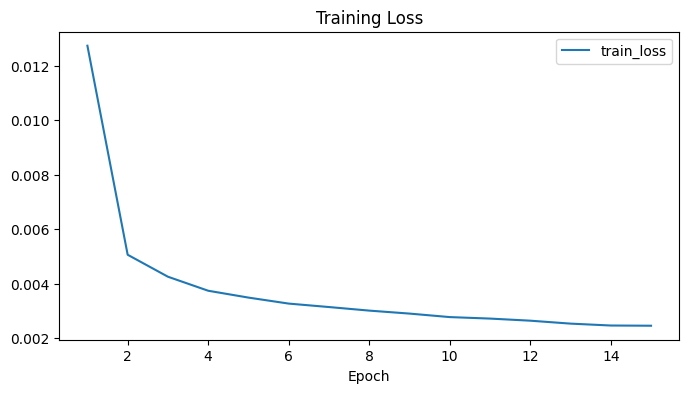

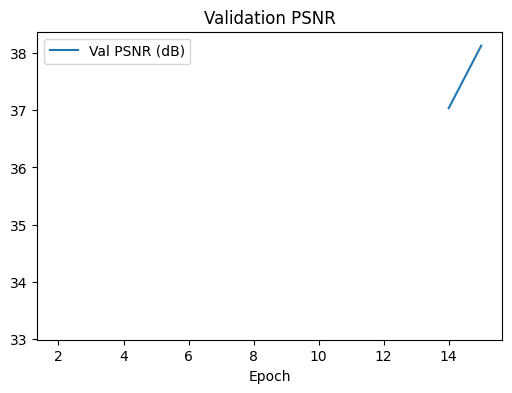

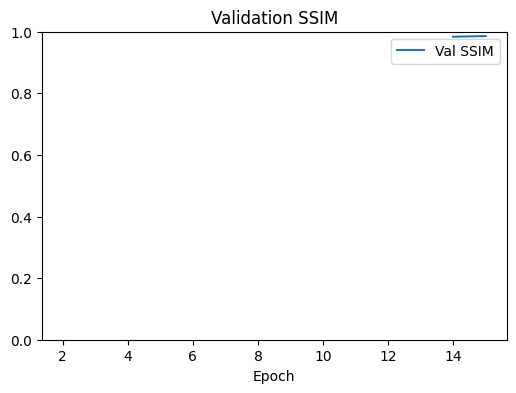

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(history["epoch"], history["train_loss"], label="train_loss")
plt.xlabel("Epoch")
plt.legend()
plt.title("Training Loss")
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(history["epoch"], history["val_psnr"], label="Val PSNR (dB)")
plt.xlabel("Epoch")
plt.legend()
plt.title("Validation PSNR")
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(history["epoch"], history["val_ssim"], label="Val SSIM")
plt.xlabel("Epoch")
plt.legend()
plt.ylim(0.0, 1.0)
plt.title("Validation SSIM")
plt.show()

<font size=7 color="#5499C7">Metrics</font>

We report PSNR (dB) and SSIM for validation and test sets.


<font size=6 color="#5499C7">SSIM Definition</font>
<font size=5>

SSIM follows the standard definition from Wang et al. (2004) 

$$SSIM(x, y) = ((2μxμy + C1)(2σxy + C2)) / ((μx^2 + μy^2 + C1)(σx^2 + σy^2 + C2))$$

computed per-channel and averaged.

</font>


<font size=7 color="#5499C7">Context</font>

The table below summarizes the performance of the trained model compared to the baseline (input-as-output) for both validation and test datasets.
Run the evaluation cell to populate metrics after training.


In [10]:
val_metrics = evaluate_model(val_loader, generator, max_batches=EVAL_MAX_BATCHES)
test_metrics = evaluate_model(test_loader, generator, max_batches=EVAL_MAX_BATCHES)

baseline_val = evaluate_model(val_loader, generator, max_batches=BASELINE_EVAL_MAX_BATCHES, baseline=True)
baseline_test = evaluate_model(test_loader, generator, max_batches=BASELINE_EVAL_MAX_BATCHES, baseline=True)

print("Validation metrics:", val_metrics)
print("Test metrics:", test_metrics)
print("Baseline (input-as-output) validation:", baseline_val)
print("Baseline (input-as-output) test:", baseline_test)

Validation metrics: {'psnr': 38.02613830566406, 'ssim': 0.9854202270507812, 'l1': 0.0045476616360247135, 'psnr_masked': 35.260311126708984, 'ssim_masked': 0.9917173385620117}
Test metrics: {'psnr': 37.80817794799805, 'ssim': 0.985683262348175, 'l1': 0.0045682517811656, 'psnr_masked': 34.729095458984375, 'ssim_masked': 0.9919349551200867}
Baseline (input-as-output) validation: {'psnr': 17.840253829956055, 'ssim': 0.9507129192352295, 'l1': 0.02735172025859356, 'psnr_masked': 3.384272336959839, 'ssim_masked': 0.9480375647544861}
Baseline (input-as-output) test: {'psnr': 18.59789276123047, 'ssim': 0.9513109922409058, 'l1': 0.02532610297203064, 'psnr_masked': 4.142364501953125, 'ssim_masked': 0.9485740661621094}
